# Core feature panel: refit of the existing collections

Step 0 of the 20 Oct plan (project note `next-steps-plan-2026-10-20`). Every saved collection is refitted with the four-feature core panel from `feature-panel-proposal-2026-10-20`. The results are used to write down, before any rule comparison, which selection rule should win for each algorithm (last section).

**Core panel**

| Axis | Column | Reading |
|---|---|---|
| Evidence volume | `seed_nonseed_degree_mean` | More clues |
| Reach | `seed_harmonic_mean`, adjusted for degree | Seeds central for their degree |
| Concentration vs. coverage | `nonseed_witness_pair_mass_mean`, adjusted for degree | Positive: clustered seeds help. Negative: spread-out seeds help |
| Distinguishability | signature uniqueness at cap 3 (cap 2 where cap 3 is saturated), adjusted for degree | Seeds tell vertices apart |

"Adjusted for degree" means the residual from a straight-line fit on seed degree among the collection's uniform random sets. Each coefficient is therefore an effect at fixed degree. At fixed degree, coverage is the mirror image of pair mass, so one axis covers both hypotheses.

**Collections** (one fixed graph pair each):

| Collection | Algorithm | Graphs | Runs per set | Random sets |
|---|---|---|---|---|
| `sgm_pilot_400` | SGM (FAQ) | Mean degree about 5–6, ρ 0.62–0.7 | 5 | 120 |
| `sgm_fixed_pairs_2026-10-13` | SGM (FAQ) and GOAT | Mean degree 16, ρ 0.4–0.5 | 1 | 600 |
| `percolation_fixed_pairs_2026-10-07` | Percolation (ExpandWhenStuck, r = 2) | Mean degree about 12, ρ 0.62–0.7 | 1 | 600 |

**Outcomes.**
- SGM: success means unseeded accuracy of at least 0.90. The pilot is modelled as a success count out of 5 runs.
- Percolation: by default the upper-mode label (accuracy of at least 0.50) recommended on 7 Oct, because 0.90 splits the upper mode. Change `PERCOLATION_LABEL` to switch.

Model fits use the uniform random sets only. The degree-weighted and degree-controlled sets are summarised separately in section 5. All features come from the saved CSVs. Graph A's saved file is read only for the hub check in section 7.

In [1]:
import json
import os
import tempfile
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'sgm_matplotlib_cache'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import binomtest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

EXPERIMENT_DIR = Path.cwd().resolve()
if EXPERIMENT_DIR.name != 'fixed_pair_seed_set_classification':
    EXPERIMENT_DIR = EXPERIMENT_DIR / 'fixed_pair_seed_set_classification'
DATA_DIR = EXPERIMENT_DIR / 'data'

MODELS = ['sparse_er', 'paper_pa', 'chung_lu']
MODEL_LABELS = {'sparse_er': 'ER', 'paper_pa': 'PAPER', 'chung_lu': 'Chung-Lu'}
SGM_PAIR_SEEDS = {'sparse_er': 88424077, 'paper_pa': 7301002, 'chung_lu': 18472911}
PERCOLATION_PAIR_SEEDS = {'sparse_er': 4192889773, 'paper_pa': 424242, 'chung_lu': 3165569293}

PERCOLATION_LABEL = 'upper_mode'  # 'upper_mode' (accuracy >= 0.5) or 'success' (accuracy >= 0.9)
SIGNATURE_SATURATION = 0.99       # use cap 2 when mean cap-3 uniqueness over random sets exceeds this
N_BOOTSTRAP = 1000
CV_SPLITS, CV_REPEATS = 5, 10
RANDOM_STATE = 2026

AXES = ['degree', 'harmonic', 'pair mass', 'signature']
FULL_PANEL = [
    'seed_nonseed_degree_mean', 'seed_harmonic_mean', 'nonseed_covered_fraction',
    'nonseed_witness_overlap_fraction', 'nonseed_witness_pair_mass_mean',
    'nonseed_nearest_seed_distance_mean', 'nonseed_three_hop_seed_count_mean',
    'nonseed_distance_signature_unique_fraction_r3', 'seed_nonseed_neighborhood_jaccard_mean',
    'nonseed_distance_signature_unique_fraction_r2', 'nonseed_distance_signature_unique_fraction_r4',
]
SIGNATURE_COLUMNS = {
    2: 'nonseed_distance_signature_unique_fraction_r2',
    3: 'nonseed_distance_signature_unique_fraction_r3',
}
ALGORITHM_COLORS = {'FAQ sparse': '#4C78A8', 'FAQ dense': '#72B7B2', 'GOAT dense': '#F58518',
                    'Percolation': '#54A24B'}

## 1. Load and verify the collections

In [2]:
def collection_specs():
    specs = []
    for model in MODELS:
        specs.append({'group': 'FAQ sparse', 'model': model, 'kind': 'pilot',
                      'csv': DATA_DIR / 'sgm_pilot_400' / f'{model}_seed_sets.csv',
                      'graph': DATA_DIR / 'sgm_pilot_400' / 'graph_pairs' / f'{model}_problem.npz'})
    for solver, group in [('faq', 'FAQ dense'), ('goat', 'GOAT dense')]:
        for model in MODELS:
            folder = (DATA_DIR / 'sgm_fixed_pairs_2026-10-13' / solver / model /
                      f'pair_1_seed_{SGM_PAIR_SEEDS[model]}')
            graph = (DATA_DIR / 'sgm_fixed_pairs_2026-10-13' / 'graph_pairs' / model /
                     f'pair_seed_{SGM_PAIR_SEEDS[model]}' / f'{model}_problem.npz')
            specs.append({'group': group, 'model': model, 'kind': 'single',
                          'csv': folder / f'{model}_seed_sets.csv', 'graph': graph})
    for model in MODELS:
        folder = (DATA_DIR / 'percolation_fixed_pairs_2026-10-07' / model /
                  f'pair_1_seed_{PERCOLATION_PAIR_SEEDS[model]}')
        specs.append({'group': 'Percolation', 'model': model, 'kind': 'percolation',
                      'csv': folder / f'{model}_percolation_seed_sets.csv',
                      'graph': folder / 'graph_pairs' / f'{model}_problem.npz'})
    for spec in specs:
        spec['label'] = f"{spec['group']} · {MODEL_LABELS[spec['model']]}"
    return specs


def read_flag(series):
    mapped = series.astype(str).str.strip().str.lower().map(
        {'true': 1, 'false': 0, '1': 1, '0': 0, '1.0': 1, '0.0': 0})
    if mapped.isna().any():
        raise ValueError('Unreadable boolean values.')
    return mapped.astype(int)


def load_collection(spec):
    csv_path = spec['csv']
    metadata_path = csv_path.with_name(csv_path.stem + '.metadata.json')
    if not csv_path.exists() or not metadata_path.exists():
        raise FileNotFoundError(f"Missing collection files for {spec['label']}: {csv_path}")
    data = pd.read_csv(csv_path)
    metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
    problems = []
    if metadata.get('rows') != len(data):
        problems.append('row count differs from the metadata')
    if 'status' in metadata and metadata['status'] != 'complete':
        problems.append(f"status is {metadata['status']!r}")
    if data['seed_vertices_graph1'].duplicated().any():
        problems.append('duplicate seed sets')
    if problems:
        raise ValueError(f"{spec['label']}: " + '; '.join(problems))

    if spec['kind'] == 'pilot':
        trials = data['sgm_run_count'].astype(int)
        successes = (data['sgm_success_rate'] * trials).round().astype(int)
    elif spec['kind'] == 'single':
        trials = pd.Series(1, index=data.index)
        successes = read_flag(data['sgm_success'])
    else:
        cutoff = 0.5 if PERCOLATION_LABEL == 'upper_mode' else 0.9
        trials = pd.Series(1, index=data.index)
        successes = data['final_unseeded_accuracy'].ge(cutoff).astype(int)
    return data.assign(successes=successes, trials=trials, rate=successes / trials)


specs = collection_specs()
collections = {spec['label']: load_collection(spec) for spec in specs}
spec_by_label = {spec['label']: spec for spec in specs}

overview = []
for label, data in collections.items():
    counts = data['sampling_strategy'].value_counts()
    random_sets = data[data['sampling_strategy'].eq('random')]
    overview.append({
        'collection': label,
        'seeds k': int(data['n_seeds'].iloc[0]),
        'runs per set': int(data['trials'].iloc[0]),
        'random': int(counts.get('random', 0)),
        'degree-weighted': int(counts.get('degree_weighted', 0)),
        'degree-controlled': int(counts.get('degree_controlled', 0)),
        'swap-path': int(counts.get('swap_path', 0)),
        'random-set success': random_sets['successes'].sum() / random_sets['trials'].sum(),
    })
overview = pd.DataFrame(overview).set_index('collection')
display(overview.round(3))

,seeds k,runs per set,random,degree-weighted,degree-controlled,swap-path,random-set success
collection,,,,,,,
FAQ sparse · ER,30,5,120,160,40,80,0.500
FAQ sparse · PAPER,16,5,120,160,40,80,0.542
FAQ sparse · Chung-Lu,22,5,120,160,40,80,0.308
FAQ dense · ER,29,1,600,200,200,0,0.737
FAQ dense · PAPER,31,1,600,200,200,0,0.530
FAQ dense · Chung-Lu,27,1,600,200,200,0,0.692
GOAT dense · ER,12,1,600,200,200,0,0.668
GOAT dense · PAPER,12,1,600,200,200,0,0.270
GOAT dense · Chung-Lu,9,1,600,200,200,0,0.672


## 2. Core features, degree adjustment and collinearity

The signature cap is chosen without looking at outcomes. Cap 3 is used unless its mean over random sets exceeds `SIGNATURE_SATURATION`, in which case cap 2 is used. For each collection, the degree adjustment is fitted on the random sets and then applied to every set. The table compares the largest variance inflation factor (VIF) among random sets for:
- the full recorded panel (constant columns dropped);
- the four raw core features;
- the four core features after degree adjustment.

In [3]:
def build_core(data):
    random_mask = data['sampling_strategy'].eq('random')
    cap = 3
    if data.loc[random_mask, SIGNATURE_COLUMNS[3]].mean() > SIGNATURE_SATURATION:
        if SIGNATURE_COLUMNS[2] not in data:
            raise ValueError('Cap 3 is saturated and no cap-2 column is recorded.')
        cap = 2
    raw = pd.DataFrame({
        'degree': data['seed_nonseed_degree_mean'],
        'harmonic': data['seed_harmonic_mean'],
        'pair mass': data['nonseed_witness_pair_mass_mean'],
        'signature': data[SIGNATURE_COLUMNS[cap]],
    })
    adjusted = raw.copy()
    for axis in ['harmonic', 'pair mass', 'signature']:
        slope, intercept = np.polyfit(raw.loc[random_mask, 'degree'], raw.loc[random_mask, axis], 1)
        adjusted[axis] = raw[axis] - (intercept + slope * raw['degree'])
    center = adjusted[random_mask].mean()
    scale = adjusted[random_mask].std(ddof=0)
    return raw, (adjusted - center) / scale, cap


def max_vif(frame):
    frame = frame.loc[:, frame.std(ddof=0) > 0]
    X = ((frame - frame.mean()) / frame.std(ddof=0)).to_numpy(float)
    values = {}
    for j, column in enumerate(frame.columns):
        design = np.column_stack([np.ones(len(X)), np.delete(X, j, axis=1)])
        coef, *_ = np.linalg.lstsq(design, X[:, j], rcond=None)
        r2 = 1 - np.var(X[:, j] - design @ coef) / np.var(X[:, j])
        values[column] = np.inf if r2 > 1 - 1e-12 else 1 / (1 - r2)
    worst = max(values, key=values.get)
    return values[worst], worst


core_raw, core_z, signature_cap = {}, {}, {}
vif_rows = []
for label, data in collections.items():
    core_raw[label], core_z[label], signature_cap[label] = build_core(data)
    random_mask = data['sampling_strategy'].eq('random')
    full_columns = [column for column in FULL_PANEL if column in data]
    full_vif, full_worst = max_vif(data.loc[random_mask, full_columns])
    vif_rows.append({
        'collection': label,
        'signature cap': signature_cap[label],
        'full panel: max VIF': full_vif,
        'full panel: worst column': full_worst.replace('nonseed_', '').replace('seed_', ''),
        'core raw: max VIF': max_vif(core_raw[label][random_mask])[0],
        'core adjusted: max VIF': max_vif(core_z[label][random_mask])[0],
    })
display(pd.DataFrame(vif_rows).set_index('collection').round(2))

,signature cap,full panel: max VIF,full panel: worst column,core raw: max VIF,core adjusted: max VIF
collection,,,,,
FAQ sparse · ER,3,899.23,degree_mean,6.34,1.61
FAQ sparse · PAPER,3,3905.84,degree_mean,3.71,1.92
FAQ sparse · Chung-Lu,3,1710.75,degree_mean,3.93,1.14
FAQ dense · ER,2,3905.62,covered_fraction,9.02,1.10
FAQ dense · PAPER,2,8122.26,covered_fraction,8.19,1.21
FAQ dense · Chung-Lu,2,1714.23,covered_fraction,8.44,1.61
GOAT dense · ER,3,1857.16,degree_mean,13.45,1.22
GOAT dense · PAPER,3,1851.13,degree_mean,13.57,1.24
GOAT dense · Chung-Lu,3,2017.80,degree_mean,7.61,1.67


## 3. Effects beyond degree among random sets

The model is a logistic regression of success on the four standardised core features: degree, plus the three degree-adjusted axes. It is fitted to the random sets of each collection; the pilot is fitted as a binomial count out of 5 runs. Coefficients are log-odds per standard deviation of the random sets. A positive value means higher values go with success at fixed degree.

Intervals are 95% percentile bootstraps over seed sets. The fit is effectively unpenalised (C = 10⁶).

,degree,harmonic | degree,pair mass | degree,signature | degree
collection,,,,
FAQ sparse · ER,"+0.62 [+0.36, +0.91]","+0.26 [-0.02, +0.70]","-0.09 [-0.37, +0.16]","-0.08 [-0.50, +0.25]"
FAQ sparse · PAPER,"+0.36 [+0.12, +0.66]","-0.14 [-0.46, +0.17]","+0.05 [-0.19, +0.32]","+0.18 [-0.09, +0.42]"
FAQ sparse · Chung-Lu,"+0.63 [+0.38, +0.93]","+0.06 [-0.26, +0.54]","+0.11 [-0.24, +0.45]","+0.55 [+0.21, +0.91]"
FAQ dense · ER,"+0.44 [+0.28, +0.66]","+0.03 [-0.17, +0.23]","+0.08 [-0.11, +0.27]","+0.12 [-0.07, +0.30]"
FAQ dense · PAPER,"+0.54 [+0.36, +0.72]","-0.03 [-0.21, +0.13]","-0.05 [-0.22, +0.13]","+0.31 [+0.14, +0.50]"
FAQ dense · Chung-Lu,"+0.24 [+0.06, +0.45]","+0.39 [+0.16, +0.63]","-0.05 [-0.29, +0.18]","+0.16 [-0.01, +0.34]"
GOAT dense · ER,"+0.26 [+0.08, +0.44]","+0.14 [-0.05, +0.33]","+0.12 [-0.07, +0.31]","+0.12 [-0.06, +0.32]"
GOAT dense · PAPER,"+0.47 [+0.30, +0.65]","-0.17 [-0.39, +0.03]","+0.06 [-0.13, +0.26]","+0.13 [-0.06, +0.33]"
GOAT dense · Chung-Lu,"-0.18 [-0.36, -0.01]","-0.16 [-0.37, +0.06]","+0.04 [-0.15, +0.26]","+0.42 [+0.23, +0.63]"


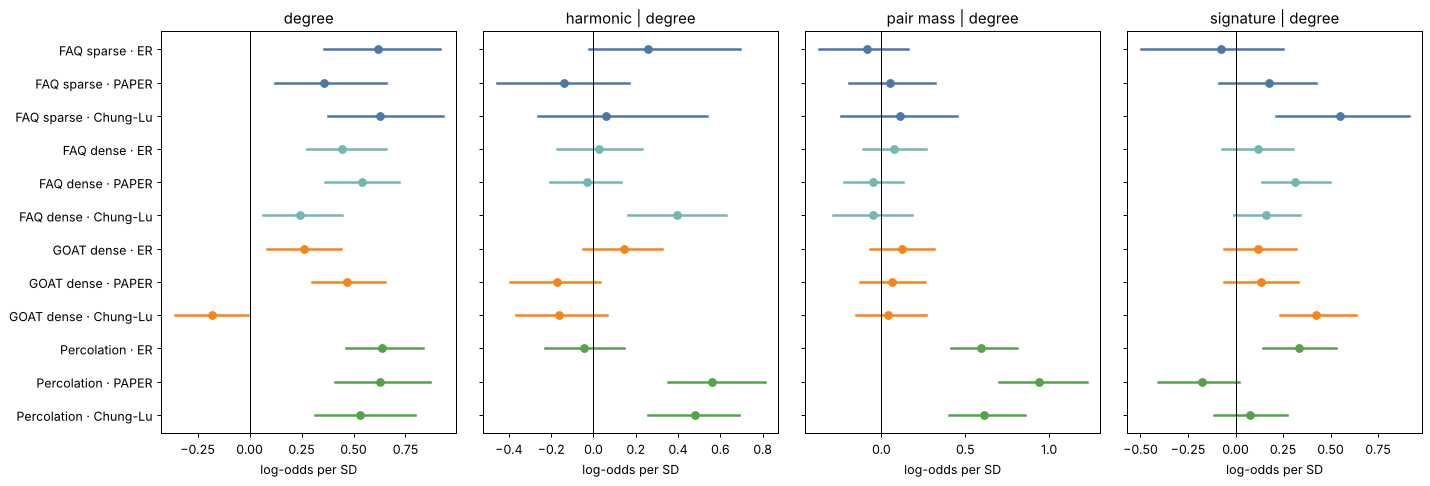

In [4]:
def binomial_rows(X, successes, trials):
    X2 = np.vstack([X, X])
    y2 = np.r_[np.ones(len(X)), np.zeros(len(X))]
    w2 = np.r_[successes, trials - successes].astype(float)
    keep = w2 > 0
    return X2[keep], y2[keep], w2[keep]


def fit_coefficients(X, successes, trials):
    X2, y2, w2 = binomial_rows(X, successes, trials)
    model = LogisticRegression(C=1e6, max_iter=5000)
    model.fit(X2, y2, sample_weight=w2)
    return model.coef_[0]


rng = np.random.default_rng(RANDOM_STATE)
effect_rows = []
for label, data in collections.items():
    random_mask = data['sampling_strategy'].eq('random').to_numpy()
    X = core_z[label].loc[random_mask, AXES].to_numpy(float)
    s = data.loc[random_mask, 'successes'].to_numpy()
    t = data.loc[random_mask, 'trials'].to_numpy()
    estimate = fit_coefficients(X, s, t)
    draws = np.array([
        fit_coefficients(X[idx], s[idx], t[idx])
        for idx in (rng.integers(0, len(X), len(X)) for _ in range(N_BOOTSTRAP))
    ])
    low, high = np.percentile(draws, [2.5, 97.5], axis=0)
    for j, axis in enumerate(AXES):
        effect_rows.append({'collection': label, 'group': spec_by_label[label]['group'], 'axis': axis,
                            'estimate': estimate[j], 'low': low[j], 'high': high[j]})
effects = pd.DataFrame(effect_rows)

formatted = effects.assign(
    value=lambda f: f.apply(lambda r: f"{r.estimate:+.2f} [{r.low:+.2f}, {r.high:+.2f}]", axis=1))
effects_table = formatted.pivot(index='collection', columns='axis', values='value')
effects_table = effects_table.loc[list(collections), AXES]
effects_table.columns = ['degree', 'harmonic | degree', 'pair mass | degree', 'signature | degree']
display(effects_table)

fig, axes = plt.subplots(1, 4, figsize=(16, 5.5), sharey=True)
labels = list(collections)
positions = np.arange(len(labels))[::-1]
for ax, axis in zip(axes, AXES):
    part = effects[effects['axis'].eq(axis)].set_index('collection').loc[labels]
    for y, (label, row) in zip(positions, part.iterrows()):
        color = ALGORITHM_COLORS[row['group']]
        ax.plot([row['low'], row['high']], [y, y], color=color, linewidth=2)
        ax.plot(row['estimate'], y, 'o', color=color)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(axis if axis == 'degree' else f'{axis} | degree')
    ax.set_xlabel('log-odds per SD')
axes[0].set_yticks(positions)
axes[0].set_yticklabels(labels)
plt.tight_layout()
plt.show()

## 4. Does the core panel predict as well as the full panel?

Repeated stratified 5-fold cross-validation on the random sets, with 10 repeats. AUC is computed over runs, so a pilot set contributes 5 labelled runs. A logistic model with degree included spans the same space with raw or degree-adjusted features, so the raw core features are used here (light L2, C = 1).

In [5]:
def cv_auc(frame, successes, trials):
    X = frame.to_numpy(float)
    strata = (successes / trials >= 0.5).astype(int)
    scores = []
    for repeat in range(CV_REPEATS):
        folds = StratifiedKFold(CV_SPLITS, shuffle=True, random_state=RANDOM_STATE + repeat)
        for train, test in folds.split(X, strata):
            model = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000))
            X2, y2, w2 = binomial_rows(X[train], successes[train], trials[train])
            model.fit(X2, y2, logisticregression__sample_weight=w2)
            p = model.predict_proba(X[test])[:, 1]
            p_rows, y_test, w_test = binomial_rows(p[:, None], successes[test], trials[test])
            scores.append(roc_auc_score(y_test, p_rows[:, 0], sample_weight=w_test))
    return np.mean(scores)


auc_rows = []
for label, data in collections.items():
    random_mask = data['sampling_strategy'].eq('random')
    s = data.loc[random_mask, 'successes'].to_numpy()
    t = data.loc[random_mask, 'trials'].to_numpy()
    full = data.loc[random_mask, [c for c in FULL_PANEL if c in data]]
    full = full.loc[:, full.std(ddof=0) > 0]
    raw = core_raw[label][random_mask]
    auc_rows.append({
        'collection': label,
        'degree only': cv_auc(raw[['degree']], s, t),
        'core panel (4)': cv_auc(raw[AXES], s, t),
        'full panel': cv_auc(full, s, t),
        'full panel columns': full.shape[1],
    })
auc_table = pd.DataFrame(auc_rows).set_index('collection')
display(auc_table.round(3))

,degree only,core panel (4),full panel,full panel columns
collection,,,,
FAQ sparse · ER,0.649,0.652,0.645,9
FAQ sparse · PAPER,0.601,0.585,0.568,9
FAQ sparse · Chung-Lu,0.667,0.682,0.675,9
FAQ dense · ER,0.621,0.604,0.598,11
FAQ dense · PAPER,0.637,0.649,0.644,11
FAQ dense · Chung-Lu,0.580,0.620,0.608,11
GOAT dense · ER,0.569,0.573,0.578,11
GOAT dense · PAPER,0.627,0.624,0.602,11
GOAT dense · Chung-Lu,0.532,0.602,0.574,11


## 5. Constructed sets

**Degree weighting.** Each degree-weighted set draws seeds with probability proportional to degree^γ, which spreads seed degree far beyond the random sets. The first table gives the success rate by γ. The final column is success at γ = 3 minus the random-set rate.

**Degree-matched contrasts.** Each pair holds seed degree roughly fixed and takes the low and high tail of one feature. A high-tail win means the high-feature set did better.
- At fixed degree, a coverage contrast is the mirror image of a pair-mass contrast.
- Ties (same outcome) are counted but excluded from the sign test.
- The pilot's contrasts were matched on total degree, not on seed–non-seed degree. Its mean degree gap shows the residual difference.

,random,gamma -1,gamma -0.5,gamma 0.5,gamma 1,gamma 2,gamma 3,gamma 3 - random
collection,,,,,,,,
FAQ sparse · ER,0.50,0.08,0.30,0.73,0.84,0.88,0.98,0.48
FAQ sparse · PAPER,0.54,0.38,0.41,0.64,0.81,0.78,0.77,0.23
FAQ sparse · Chung-Lu,0.31,0.05,0.21,0.41,0.61,0.85,0.89,0.58
FAQ dense · ER,0.74,0.76,0.65,0.88,0.94,0.88,1.00,0.26
FAQ dense · PAPER,0.53,0.29,0.53,0.76,0.88,0.91,1.00,0.47
FAQ dense · Chung-Lu,0.69,0.41,0.71,0.82,0.79,0.94,1.00,0.31
GOAT dense · ER,0.67,0.65,0.62,0.82,0.73,0.73,0.82,0.15
GOAT dense · PAPER,0.27,0.26,0.35,0.27,0.21,0.48,0.67,0.40
GOAT dense · Chung-Lu,0.67,0.59,0.68,0.61,0.67,0.67,0.64,-0.04


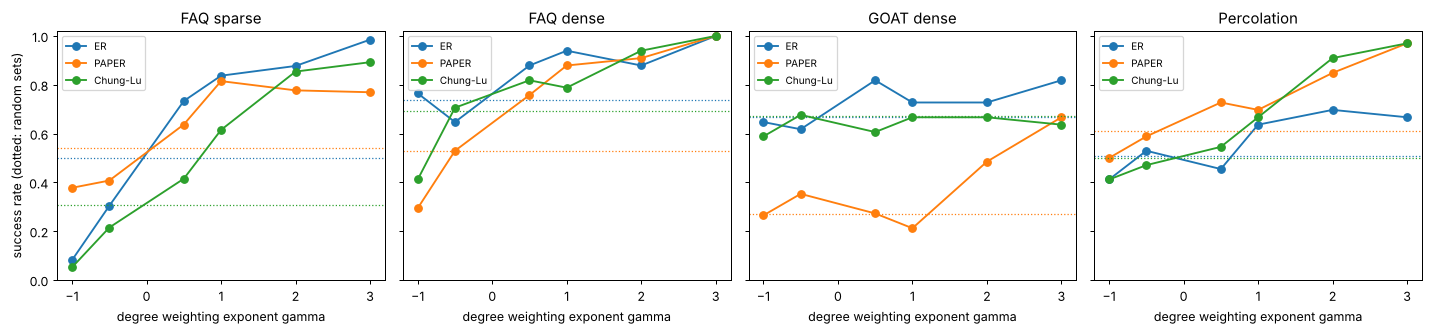

In [6]:
gamma_rows = []
for label, data in collections.items():
    weighted = data[data['sampling_strategy'].eq('degree_weighted')]
    random_sets = data[data['sampling_strategy'].eq('random')]
    totals = weighted.groupby('degree_gamma')[['successes', 'trials']].sum()
    rates = totals['successes'] / totals['trials']
    row = {'collection': label, 'random': random_sets['successes'].sum() / random_sets['trials'].sum()}
    row.update({f'gamma {gamma:g}': rate for gamma, rate in rates.items()})
    row['gamma 3 - random'] = rates.get(3.0, np.nan) - row['random']
    gamma_rows.append(row)
gamma_table = pd.DataFrame(gamma_rows).set_index('collection')
display(gamma_table.round(2))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, group in zip(axes, ALGORITHM_COLORS):
    for label in [l for l in collections if spec_by_label[l]['group'] == group]:
        row = gamma_table.loc[label]
        gammas = [float(c.split()[1]) for c in gamma_table.columns if c.startswith('gamma ') and ' - ' not in c]
        values = [row[f'gamma {g:g}'] for g in gammas]
        line, = ax.plot(gammas, values, marker='o', label=MODEL_LABELS[spec_by_label[label]['model']])
        ax.axhline(row['random'], color=line.get_color(), linestyle=':', linewidth=1)
    ax.set_title(group)
    ax.set_xlabel('degree weighting exponent gamma')
    ax.set_ylim(0, 1.02)
    ax.legend(fontsize=8)
axes[0].set_ylabel('success rate (dotted: random sets)')
plt.tight_layout()
plt.show()

In [7]:
def contrast_pairs(data):
    controlled = data[data['sampling_strategy'].eq('degree_controlled')].copy()
    if 'contrast_pair_id' in controlled and controlled['contrast_pair_id'].notna().all():
        controlled['pair'] = controlled['contrast_pair_id']
    else:  # sampler v1 (pilot): each low set is followed by its high partner
        controlled = controlled.sort_values('candidate_id')
        controlled['pair'] = np.arange(len(controlled)) // 2
    rows = []
    for _, pair in controlled.groupby('pair'):
        tails = pair.set_index('contrast_tail')
        if set(tails.index) != {'low', 'high'} or pair['contrast_feature'].nunique() != 1:
            raise ValueError('Malformed contrast pair.')
        rows.append({
            'feature': pair['contrast_feature'].iloc[0],
            'difference': tails.loc['high', 'rate'] - tails.loc['low', 'rate'],
            'degree gap': (tails.loc['high', 'seed_nonseed_degree_mean']
                           - tails.loc['low', 'seed_nonseed_degree_mean']),
        })
    return pd.DataFrame(rows)


contrast_rows = []
for label, data in collections.items():
    pairs = contrast_pairs(data)
    for feature, part in pairs.groupby('feature'):
        wins = int((part['difference'] > 0).sum())
        losses = int((part['difference'] < 0).sum())
        contrast_rows.append({
            'collection': label, 'feature': feature, 'pairs': len(part),
            'high wins': wins, 'low wins': losses, 'ties': len(part) - wins - losses,
            'mean difference': part['difference'].mean(),
            'sign-test p': binomtest(wins, wins + losses).pvalue if wins + losses else np.nan,
            'mean degree gap': part['degree gap'].mean(),
        })
contrasts = pd.DataFrame(contrast_rows)
display(contrasts.set_index(['collection', 'feature']).round(3))

pairs  high wins  low wins  ties  mean difference  sign-test p  mean degree gap
collection             feature                                                                                              
FAQ sparse · ER        coverage                  7          4         1     2            0.114        0.375            0.495
                       pair_mass                 7          1         2     4           -0.000        1.000            0.171
                       unique_signatures_r3      6          4         0     2            0.267        0.125            0.289
FAQ sparse · PAPER     coverage                  7          3         3     1            0.143        1.000            0.482
                       pair_mass                 7          1         6     0           -0.400        0.125            0.107
                       unique_signatures_r3      6          3         1     2            0.167        0.625            0.167
FAQ sparse · Chung-Lu  coverage                  7          2         2     3           -0.086        1.000            0.584
                       pair_mass                 7          3         0     4            0.171        0.250            0.143
                       unique_signatures_r3      6          4         0     2            0.433        0.125            0.258
FAQ dense · ER         coverage                 33          2         5    26           -0.091        0.453            0.000
                       pair_mass                34          8         8    18            0.000        1.000            0.000
                       unique_signatures_r3     33          5         5    23            0.000        1.000            0.000
FAQ dense · PAPER      coverage                 33          5        10    18           -0.152        0.302            0.000
                       pair_mass                34          6         8    20           -0.059        0.791            0.000
                       unique_signatures_r3     33         10         7    16            0.091        0.629            0.000
FAQ dense · Chung-Lu   coverage                 33          5         9    19           -0.121        0.424            0.000
                       pair_mass                34          9         7    18            0.059        0.804            0.000
                       unique_signatures_r3     33         11         3    19            0.242        0.057            0.000
GOAT dense · ER        coverage                 33          6         4    23            0.061        0.754            0.000
                       pair_mass                34         12         2    20            0.294        0.013            0.000
                       unique_signatures_r3     33         11         5    17            0.182        0.210            0.000
GOAT dense · PAPER     coverage                 33          6         7    20           -0.030        1.000            0.000
                       pair_mass                34          9         5    20            0.118        0.424            0.000
                       unique_signatures_r3     33         11         5    17            0.182        0.210            0.000
GOAT dense · Chung-Lu  coverage                 33         12         5    16            0.212        0.143            0.000
                       pair_mass                34         10         2    22            0.235        0.039            0.000
                       unique_signatures_r3     33         13         7    13            0.182        0.263            0.000
Percolation · ER       coverage                 33          0        18    15           -0.545        0.000            0.000
                       pair_mass                34         14         1    19            0.382        0.001            0.000
                       unique_signatures_r3     33         10         4    19            0.182        0.180            0.000
Percolation · PAPER    coverage              

## 6. Summary by collection

How to read the summary:
- **Axis entries:** `+` or `−` when the 95% bootstrap interval excludes zero, otherwise `·`.
- **Contrast entries:** high-tail wins against low-tail wins, with `*` when the sign test gives p < 0.05.
- **Signature:** the cap that was used.

In [8]:
def axis_flag(label, axis):
    row = effects[(effects['collection'] == label) & (effects['axis'] == axis)].iloc[0]
    sign = '+' if row['low'] > 0 else '−' if row['high'] < 0 else '·'
    return f"{sign} ({row['estimate']:+.2f})"


def contrast_flag(label, feature):
    part = contrasts[(contrasts['collection'] == label) & (contrasts['feature'] == feature)]
    if part.empty:
        return ''
    row = part.iloc[0]
    star = '*' if row['sign-test p'] < 0.05 else ''
    return f"{row['high wins']}–{row['low wins']}{star}"


summary_rows = []
for label in collections:
    summary_rows.append({
        'collection': label,
        'degree': axis_flag(label, 'degree'),
        'harmonic | deg': axis_flag(label, 'harmonic'),
        'pair mass | deg': axis_flag(label, 'pair mass'),
        'signature | deg': f"{axis_flag(label, 'signature')}, r{signature_cap[label]}",
        'contrast: pair mass': contrast_flag(label, 'pair_mass'),
        'contrast: coverage': contrast_flag(label, 'coverage'),
        'contrast: signature r3': contrast_flag(label, 'unique_signatures_r3'),
        'gamma 3 - random': round(gamma_table.loc[label, 'gamma 3 - random'], 2),
        'CV AUC degree / core': f"{auc_table.loc[label, 'degree only']:.2f} / {auc_table.loc[label, 'core panel (4)']:.2f}",
    })
summary = pd.DataFrame(summary_rows).set_index('collection')
display(summary)

,degree,harmonic | deg,pair mass | deg,signature | deg,contrast: pair mass,contrast: coverage,contrast: signature r3,gamma 3 - random,CV AUC degree / core
collection,,,,,,,,,
FAQ sparse · ER,+ (+0.62),· (+0.26),· (-0.09),"· (-0.08), r3",1–2,4–1,4–0,0.48,0.65 / 0.65
FAQ sparse · PAPER,+ (+0.36),· (-0.14),· (+0.05),"· (+0.18), r3",1–6,3–3,3–1,0.23,0.60 / 0.59
FAQ sparse · Chung-Lu,+ (+0.63),· (+0.06),· (+0.11),"+ (+0.55), r3",3–0,2–2,4–0,0.58,0.67 / 0.68
FAQ dense · ER,+ (+0.44),· (+0.03),· (+0.08),"· (+0.12), r2",8–8,2–5,5–5,0.26,0.62 / 0.60
FAQ dense · PAPER,+ (+0.54),· (-0.03),· (-0.05),"+ (+0.31), r2",6–8,5–10,10–7,0.47,0.64 / 0.65
FAQ dense · Chung-Lu,+ (+0.24),+ (+0.39),· (-0.05),"· (+0.16), r2",9–7,5–9,11–3,0.31,0.58 / 0.62
GOAT dense · ER,+ (+0.26),· (+0.14),· (+0.12),"· (+0.12), r3",12–2*,6–4,11–5,0.15,0.57 / 0.57
GOAT dense · PAPER,+ (+0.47),· (-0.17),· (+0.06),"· (+0.13), r3",9–5,6–7,11–5,0.40,0.63 / 0.62
GOAT dense · Chung-Lu,− (-0.18),· (-0.16),· (+0.04),"+ (+0.42), r3",10–2*,12–5,13–7,-0.04,0.53 / 0.60


## 7. Hub check (diagnostic, not a panel feature)

Chung–Lu under GOAT is the one collection where degree has a negative effect. This check asks whether that comes from the very top hubs. Among random sets, it compares success for sets that contain at least one of Graph A's 10 highest-degree vertices against sets that contain none. For the pilot the comparison pools runs, so its p-value is approximate.

In [9]:
from scipy.stats import fisher_exact

hub_rows = []
for label, data in collections.items():
    with np.load(spec_by_label[label]['graph']) as saved:
        degrees = saved['adjacency_graph1'].sum(axis=1)
    top_hubs = set(np.argsort(-degrees, kind='stable')[:10].tolist())
    random_sets = data[data['sampling_strategy'].eq('random')]
    has_hub = random_sets['seed_vertices_graph1'].apply(lambda s: bool(top_hubs & set(json.loads(s))))
    table = []
    row = {'collection': label, 'top-10 hub degrees': f"{int(degrees[list(top_hubs)].min())}-{int(degrees.max())}",
           'mean degree': round(float(degrees.mean()), 1)}
    for flag, name in [(True, 'with hub'), (False, 'without hub')]:
        part = random_sets[has_hub.eq(flag)]
        successes, trials = int(part['successes'].sum()), int(part['trials'].sum())
        table.append([successes, trials - successes])
        row[f'sets {name}'] = len(part)
        row[f'success {name}'] = successes / trials if trials else np.nan
    row['difference'] = row['success with hub'] - row['success without hub']
    row['Fisher p'] = fisher_exact(table)[1] if min(map(sum, table)) > 0 else np.nan
    hub_rows.append(row)
hub_table = pd.DataFrame(hub_rows).set_index('collection')
display(hub_table.round(3))

,top-10 hub degrees,mean degree,sets with hub,success with hub,sets without hub,success without hub,difference,Fisher p
collection,,,,,,,,
FAQ sparse · ER,11-13,5.9,42,0.557,78,0.469,0.088,0.049
FAQ sparse · PAPER,13-62,5.1,28,0.600,92,0.524,0.076,0.122
FAQ sparse · Chung-Lu,13-37,5.7,41,0.346,79,0.289,0.058,0.162
FAQ dense · ER,25-32,15.9,233,0.738,367,0.736,0.003,1.000
FAQ dense · PAPER,28-51,15.8,230,0.596,370,0.489,0.106,0.012
FAQ dense · Chung-Lu,48-114,15.8,217,0.705,383,0.684,0.021,0.646
GOAT dense · ER,25-32,15.9,111,0.712,489,0.658,0.053,0.316
GOAT dense · PAPER,28-51,15.8,109,0.440,491,0.232,0.208,0.000
GOAT dense · Chung-Lu,48-114,15.8,78,0.526,522,0.693,-0.168,0.004



## 8. Predictions for the rule comparison (written 20 Oct, before any rule runs)

These predictions apply at the budget where top degree succeeds about half the time. The rules are the ones in `next-steps-plan-2026-10-20`:
- random;
- top degree;
- top harmonic;
- three degree-first rules: from the top 2k vertices by degree, pick greedily for pair mass (clustered), coverage (spread) or signature uniqueness (distinguishing);
- the core-model score, kept inside its training range.

### What the refit shows

**The core panel loses nothing.**
- Its cross-validated AUC is within about 0.02 of the full 9–11-column panel in every collection (section 4), with maximum VIF 1.1–1.9 instead of 900–8,000 (section 2).
- It beats degree alone mainly for percolation (+0.08 to +0.14) and Chung–Lu GOAT (+0.07).

**Percolation** (the clearest case).
- Degree helps. Pair mass at fixed degree has the largest effect anywhere: +0.60 to +0.94 log-odds per SD.
- Degree-matched contrasts: high pair mass won 62 of 66, and high coverage lost all 64.
- Reach helps beyond degree on PAPER and Chung–Lu (+0.56, +0.48), and sets containing a top hub do better (+0.15, +0.28).
- Signature uniqueness helps on ER (+0.33).

**SGM (FAQ).**
- Degree dominates: degree-weighted sets at γ = 3 succeed 77–100% of the time.
- The only effects beyond degree are distinguishability and reach:
  - signature +0.55 on sparse Chung–Lu and +0.31 (cap 2) on dense PAPER;
  - contrasts 11–1 pooled in the sparse pilot, and 11–3 on dense Chung–Lu;
  - harmonic +0.39 on dense Chung–Lu.
- Pair mass is null, with sparse PAPER contrasts going against it (1–6). Coverage contrasts are null to slightly negative.

**GOAT** (model-specific).
- Degree helps on ER (+0.26) and PAPER (+0.47) but hurts on Chung–Lu (−0.18). The section 7 hub check locates this:
  - On Chung–Lu, random sets containing a top-10 hub (degree 48–114) succeed 53% of the time, against 69% without one.
  - On PAPER, such sets succeed 44% of the time, against 23%. PAPER's tree hubs are shared exactly between A and B; Chung–Lu hubs' edges are subject to ρ noise.
- Signature uniqueness helps clearly on Chung–Lu (+0.42) and weakly elsewhere. Contrasts were 11–5, 11–5 and 13–7.
- Pair mass is small among random sets, but its contrasts favour high pair mass: 12–2 on ER, 10–2 on Chung–Lu.

### Predicted order (best first)

| Algorithm | Model | Predicted order | Confidence |
|---|---|---|---|
| Percolation | ER | clustered > distinguishing ≥ top degree ≈ top harmonic > spread > random | High for clustered > spread; medium for clustered > top degree |
| Percolation | PAPER, Chung–Lu | clustered ≥ top harmonic ≥ top degree > distinguishing > spread > random | High for clustered > spread; medium for clustered > top degree (top-degree sets already share hub neighbourhoods) |
| SGM (FAQ) | ER | top degree ≈ top harmonic ≈ distinguishing ≈ clustered ≥ spread ≫ random | High that random is far behind; medium that nothing beats top degree by more than about 0.1 |
| SGM (FAQ) | PAPER, Chung–Lu | distinguishing ≥ top degree ≈ top harmonic ≥ spread ≥ clustered ≫ random | Low to medium for distinguishing > top degree |
| GOAT | ER | clustered ≈ distinguishing ≥ top degree > random | Low (small effects, B noise at ρ 0.5) |
| GOAT | PAPER | distinguishing ≈ clustered ≥ top degree ≫ random | Medium |
| GOAT | Chung–Lu | distinguishing without top hubs > random ≥ top degree | Medium |

In every case the model score should track the best axis rule for that algorithm, because the fitted core model is mostly degree plus that axis.

### Design implications for the rule comparison
- **Chung–Lu under GOAT:** add one hub-free variant, the distinguishing rule with the top 10 hubs removed from its candidate pool. Every degree-first pool contains the hubs that hurt GOAT there.
- **Percolation:** report ER separately. Top-degree sets in ER are scattered, so the clustered rule has the most room to beat top degree there.
- **What would count against these predictions:**
  - percolation: clustered does not beat spread, or does not at least tie top degree;
  - FAQ: any rule beats top degree by clearly more than 0.1;
  - GOAT on Chung–Lu: top degree is not below random.

### Caveats
- One graph pair per model, and the pilot has only 120 random sets.
- Random-set coefficients describe the random-set range. Degree-matched contrasts have about 33 pairs per feature, and about 7 per feature in the pilot.
- GOAT evidence comes from ρ 0.4–0.5 only.
- The hub effect is an association in one pair per model; the mechanism suggested above is a hypothesis.
